# Task 1 y Task 2 — Camas de UCI con simulación de eventos discretos

Los pacientes críticos llegan según un proceso de Poisson de tasa $\lambda$ y ocupan una cama un tiempo exponencial de media $1/\mu$ días. El hospital tiene $c$ camas y se estudian dos variantes:

- **Con espera (M/M/$c$):** si no hay cama libre, el paciente espera en urgencias.
- **Sin espera (M/M/$c$/$c$):** si no hay cama libre, el paciente es desviado.

**Grupo 10:**

- $\lambda = 3.0 + 0.2\,(9 \bmod 5) = 3.8$ pacientes/día
- $c = 17 + (9 \bmod 3) = 17$ camas
- $\mu = 0.25$ por día

Las fórmulas teóricas están en `colas.py`.

In [1]:
import math
from contextlib import contextmanager
from unittest import mock

import matplotlib.pyplot as plt
import numpy as np

import simulador
from colas import erlang_b, mmc, mmcc
from ia import simulador_ia

LAM, MU, C = 3.8, 0.25, 17
HORAS = 24

In [2]:
a = LAM / MU
rho = a / C
k_off = math.ceil(C - a) + 3
print(f"a = {a:.2f}, rho = {rho:.4f}, k_off = {k_off}")

a = 15.20, rho = 0.8941, k_off = 5


## Task 1.1. Desempeño teórico

### Variante con espera (M/M/$c$)

| Medida | Fórmula |
|---|---|
| Carga ofrecida | $a = \lambda/\mu$ |
| Utilización | $\rho = a/c$ |
| Probabilidad de esperar | $C(c,a) = \dfrac{B(c,a)}{1 - \rho\,(1 - B(c,a))}$ |
| Promedio en cola | $L_q = C(c,a)\,\dfrac{\rho}{1-\rho}$ |
| Espera en cola | $W_q = L_q/\lambda$ |
| Tiempo en el sistema | $W = W_q + 1/\mu$ |

$C(c,a)$ se obtiene a partir de $B(c,a)$, que se calcula con la recurrencia de Erlang B.

In [3]:
t = mmc(LAM, MU, C)
print(f"a  = {t['a']:.2f}")
print(f"rho = {t['rho']:.4f}")
print(f"C(c, a) = {t['C']:.4f}")
print(f"Lq = {t['Lq']:.4f} pacientes")
print(f"Wq = {t['Wq']:.4f} días = {t['Wq'] * HORAS:.2f} horas")
print(f"W  = {t['W']:.4f} días = {t['W'] * HORAS:.2f} horas")
print(f"L  = {t['L']:.4f} pacientes")

a  = 15.20
rho = 0.8941
C(c, a) = 0.5600
Lq = 4.7290 pacientes
Wq = 1.2445 días = 29.87 horas
W  = 5.2445 días = 125.87 horas
L  = 19.9290 pacientes


**RESULTADOS**

| Medida | Valor |
|---|---|
| $a$ | 15.20 |
| $\rho$ | 0.8941 |
| $C(c,a)$ | 0.5600 |
| $L_q$ | 4.729 pacientes |
| $W_q$ | 1.2445 días = **29.87 horas** |
| $W$ | 5.2445 días = **125.87 horas** |
| $L$ | 19.929 pacientes |

El 56% de los pacientes debe esperar una cama, y la espera promedio es de casi 30 horas.

### Variante sin espera (M/M/$c$/$c$)

Recurrencia de Erlang B:

$$B(0,a) = 1, \qquad B(k,a) = \frac{a\,B(k-1,a)}{k + a\,B(k-1,a)}, \quad k = 1, \dots, c$$

- Tasa efectiva de ingresos: $\lambda_{ef} = \lambda\,(1 - B(c,a))$
- Camas ocupadas en promedio: $L = \lambda_{ef}/\mu$

In [4]:
s = mmcc(LAM, MU, C)
print(f"B(c, a) = {s['B']:.4f}")
print(f"lam_ef  = {s['lam_ef']:.4f} pacientes/día")
print(f"L       = {s['L']:.4f} camas ocupadas")
print(f"Prueba: erlang_b(1, a) = {erlang_b(1, a):.6f}, a/(1+a) = {a / (1 + a):.6f}")

B(c, a) = 0.1188
lam_ef  = 3.3487 pacientes/día
L       = 13.3949 camas ocupadas
Prueba: erlang_b(1, a) = 0.938272, a/(1+a) = 0.938272


**RESULTADOS**

- $B(c,a) = 0.1188$: cerca del 12% de los pacientes es desviado.
- $\lambda_{ef} = 3.349$ pacientes/día ingresan al hospital.
- $L = 13.39$ camas ocupadas en promedio, es decir, una ocupación de $13.39/17 = 78.8\%$.

La recurrencia con una sola cama coincide con el valor exacto $a/(1+a)$.

### Verificación con la ley de Little

- Con espera: $L = \lambda W$ y $L_q = \lambda W_q$. Además, $L - L_q$ debe ser igual a las camas ocupadas, $a = \lambda/\mu$.
- Sin espera: $L = \lambda_{ef}\,W$, con $W = 1/\mu$.

In [5]:
print("Con espera:")
print(f"  L = {t['L']:.4f}, lam*W  = {LAM * t['W']:.4f}")
print(f"  Lq = {t['Lq']:.4f}, lam*Wq = {LAM * t['Wq']:.4f}")
print(f"  L - Lq = {t['L'] - t['Lq']:.4f}, a = {a:.4f}")
print("Sin espera:")
print(f"  L = {s['L']:.4f}, lam_ef*W = {s['lam_ef'] * s['W']:.4f}")
print(f"  Usando lam: lam*W = {LAM * s['W']:.4f} (error {LAM * s['W'] / s['L'] - 1:+.2%})")

Con espera:
  L = 19.9290, lam*W  = 19.9290
  Lq = 4.7290, lam*Wq = 4.7290
  L - Lq = 15.2000, a = 15.2000
Sin espera:
  L = 13.3949, lam_ef*W = 13.3949
  Usando lam: lam*W = 15.2000 (error +13.48%)


**RESULTADOS**

- Con espera, $L = \lambda W = 19.929$ y $L_q = \lambda W_q = 4.729$. La diferencia $L - L_q = 15.2 = a$ son las camas ocupadas, como se espera.
- Sin espera, $L = \lambda_{ef} W = 13.395$.

**Error al usar $\lambda$ en la variante sin espera:** se contarían también los pacientes desviados, que nunca ocupan cama, y se sobreestimarían las camas ocupadas en un 13.5% (15.2 en lugar de 13.39).

## Task 1.2. Simulador generado por IA

Se usó Codex (modelo GPT-6 Astra). El prompt, el código recibido sin modificar y las afirmaciones del agente están en la carpeta `ia/` (anexo):

- `ia/prompt.md`
- `ia/simulador_ia.py`
- `ia/afirmaciones.md`

El agente afirmó, entre otras cosas, que *"las verificaciones respaldan que el simulador es correcto"*, que *"pasó 64 comparaciones contra un cálculo independiente por paciente"* y que *"todos los valores teóricos quedaron dentro de sus respectivos intervalos del 95%"*.

## Task 1.3. Revisión del código de la IA

Se revisa `ia/simulador_ia.py` con siete puntos y pruebas cuya respuesta se conoce de antemano. Las mismas pruebas se aplican al simulador corregido (`simulador.py`).

### Prueba 1: caso determinista calculado a mano

Se reemplaza el generador aleatorio por uno que siempre devuelve la media. Con $\lambda = 1$, todos los pacientes llegan en $t = 1, 2, 3, \dots$ y la estancia es fija. Con una cama:

| Caso | Estancia | Horizonte | Valor exacto (a mano) |
|---|---|---|---|
| A, con espera | 0.25 | 100 | 99 pacientes × 0.25 días / 100 días: $L = 0.2475$ |
| B, con espera | 1.5 | 10.5 | El paciente $k$ espera $0.5(k-1)$: $W_q = 2.25$; $L_q = 15/10.5 = 1.4286$; utilización $= 9.5/10.5 = 0.9048$ |
| C, sin espera | 1.5 | 10.5 | Se desvía uno de cada dos: $B = 0.5$; utilización $= 7.5/10.5 = 0.7143$ |

En el caso A, un promedio por evento (sin ponderar por tiempo) daría $L = 0.5$. En el caso B, medir la espera desde el inicio del servicio daría $W_q = 0$, y los pacientes 8, 9 y 10 siguen esperando al llegar al horizonte.

In [6]:
class RngDeterminista:
    """Generador falso: `exponential(scale)` devuelve siempre la media `scale`."""

    def __init__(self, *args, **kwargs):
        pass

    def exponential(self, scale):
        return scale


@contextmanager
def rng_determinista():
    """Sustituye `np.random.default_rng` por `RngDeterminista` dentro del bloque."""
    with mock.patch.object(np.random, "default_rng", RngDeterminista):
        yield


casos = {
    "A": dict(lam=1.0, mu=4.0, c=1, horizonte=100.0, variante="espera"),
    "B": dict(lam=1.0, mu=1 / 1.5, c=1, horizonte=10.5, variante="espera"),
    "C": dict(lam=1.0, mu=1 / 1.5, c=1, horizonte=10.5, variante="perdida"),
}
exactos = {
    "A": {"L": 0.2475},
    "B": {"Wq": 2.25, "Lq": 15 / 10.5, "utilizacion": 9.5 / 10.5},
    "C": {"prob_bloqueo": 0.5, "utilizacion": 7.5 / 10.5},
}

print(f"{'Caso':<5}{'Medida':<13}{'Exacto':>9}{'IA':>9}{'Corregido':>11}")
with rng_determinista():
    for nombre, p in casos.items():
        r_ia = simulador_ia.simular(p["lam"], p["mu"], p["c"], p["horizonte"], 0.0, 1, p["variante"])
        r_co = simulador.simular(p["lam"], p["mu"], p["c"], p["horizonte"], 0.0, 1, p["variante"])
        for m, v in exactos[nombre].items():
            print(f"{nombre:<5}{m:<13}{v:9.4f}{r_ia[m]:9.4f}{r_co[m]:11.4f}")

Caso Medida          Exacto       IA  Corregido
A    L               0.2475   0.2475     0.2475
B    Wq              2.2500   2.2500     2.2500
B    Lq              1.4286   1.4286     1.4286
B    utilizacion     0.9048   0.9048     0.9048
C    prob_bloqueo    0.5000   0.5000     0.5000
C    utilizacion     0.7143   0.7143     0.7143


**RESULTADOS**

Ambos simuladores reproducen los seis valores exactos. Esto confirma que:

- $L$ se pondera por la duración de cada tramo (caso A).
- La espera se mide desde la llegada (caso B).
- Los pacientes que siguen en fila al llegar al horizonte se cuentan con su espera completa (caso B). Si se descartaran, se obtendría $W_q = (0 + 0.5 + \dots + 3)/7 = 1.5$ en lugar de $2.25$.

### Prueba 2: una sola cama sin espera

Con $c = 1$, la probabilidad de bloqueo exacta es $B(1,a) = \frac{a}{1+a}$. Con $\lambda = 2$ y $\mu = 1$ se tiene $a = 2$ y $B = 2/3$. Además, por la ley de Little, las camas ocupadas deben ser $L = \lambda_{ef}/\mu$ y no $\lambda/\mu = 2$.

In [7]:
a1 = 2.0
r_ia = simulador_ia.replicas(2.0, 1.0, 1, 5000, 100, 7, "perdida", 30)
r_co, d_co = simulador.replicas(2.0, 1.0, 1, 5000, 100, 7, "perdida", 30)
print(f"B exacto = {a1 / (1 + a1):.4f}")
print(f"IA:        B = {r_ia['prob_bloqueo']['media']:.4f}, IC95 = ({r_ia['prob_bloqueo']['ic95'][0]:.4f}, {r_ia['prob_bloqueo']['ic95'][1]:.4f})")
print(f"Corregido: B = {r_co['prob_bloqueo']['media']:.4f}, IC95 = ({r_co['prob_bloqueo']['ic95'][0]:.4f}, {r_co['prob_bloqueo']['ic95'][1]:.4f})")
print(f"Corregido: L = {r_co['L']['media']:.4f}, lam_ef/mu = {r_co['tasa_ingresos']['media'] / 1.0:.4f}, lam/mu = {a1:.4f}")

B exacto = 0.6667
IA:        B = 0.6663, IC95 = (0.6643, 0.6683)
Corregido: B = 0.6663, IC95 = (0.6643, 0.6683)
Corregido: L = 0.6668, lam_ef/mu = 0.6666, lam/mu = 2.0000


**RESULTADOS**

- $B$ simulado $= 0.6663$, con IC $(0.6643, 0.6683)$, que contiene el valor exacto $0.6667$.
- $L = 0.6668$ coincide con $\hat\lambda_{ef}/\mu = 0.6666$ y no con $\lambda/\mu = 2$. El código usa la tasa efectiva.

### Prueba 3: cobertura del intervalo de confianza

Si la réplica es la unidad de muestreo, el IC del 95% debe contener el valor exacto en cerca del 95% de los casos. Se repite 100 veces el cálculo del IC (30 réplicas cada vez) para $c = 1$, $\lambda = \mu = 1$, donde $B = 0.5$.

In [8]:
dentro = 0
for k in range(100):
    r = simulador_ia.replicas(1.0, 1.0, 1, 200, 20, 1000 + k, "perdida", 30)
    lo, hi = r["prob_bloqueo"]["ic95"]
    dentro += lo <= 0.5 <= hi
print(f"Cobertura del IC (IA): {dentro}%")

Cobertura del IC (IA): 95%


**RESULTADOS**

El IC contiene el valor exacto en 95 de 100 casos, lo esperado para un IC del 95%. La réplica es la unidad de muestreo.

### Prueba 4: independencia de las réplicas

Si las réplicas compartieran semilla, darían el mismo resultado y el IC tendría ancho cero.

In [9]:
semillas = np.random.SeedSequence(2026).spawn(30)
L_rep = [simulador_ia.simular(LAM, MU, C, 500, 100, s, "espera")["L"] for s in semillas]
print(f"Valores distintos de L entre 30 réplicas: {len(set(L_rep))}")
print(f"Desviación estándar de L entre réplicas: {np.std(L_rep, ddof=1):.3f}")

Valores distintos de L entre 30 réplicas: 30
Desviación estándar de L entre réplicas: 2.798


**RESULTADOS**

Las 30 réplicas dan 30 valores distintos de $L$, con desviación estándar de 2.8 pacientes. Las semillas son independientes.

### Tabla de revisión

Las líneas citadas son de `ia/simulador_ia.py`.

| Punto | ¿Se cumple? | Evidencia | Supuesto que viola si no se cumple | Prueba con la que se detecta |
|---|---|---|---|---|
| (i) Promedio ponderado por tiempo | Sí | Líneas 73–77: el área suma estado × duración del tramo. Prueba 1, caso A: $L = 0.2475$ exacto | Que todos los estados duran lo mismo, falso cuando los eventos ocurren en tiempos aleatorios | Caso determinista A: un promedio por evento daría $0.5$ |
| (ii) La réplica es la unidad de muestreo | Sí | Líneas 168–172: desviación estándar entre réplicas. Prueba 3: cobertura del 95% | Independencia entre pacientes; pacientes consecutivos tienen esperas correlacionadas y el IC sale demasiado angosto | Cobertura del IC en un caso con $B$ conocido |
| (iii) Calentamiento justificado | Parcial | Línea 74 descarta $[0, 200)$, pero el valor 200 se tomó del prompt sin ninguna justificación | Que el sistema ya está en régimen estacionario al empezar a medir; al partir vacío, la fila se subestima | Promedio móvil de $L_q$ entre réplicas (Task 1.4) |
| (iv) Semillas independientes | Sí | Línea 163: `SeedSequence.spawn`. Prueba 4: 30 valores distintos | Réplicas independientes; con la misma semilla el IC tendría ancho cero | Contar resultados distintos entre réplicas |
| (v) Tasa efectiva en la variante sin espera | Sí | Línea 192: $L = a(1-B)$; línea 124: $W_q$ entre admitidos. Prueba 2: $L = \hat\lambda_{ef}/\mu$ | Que todos los que llegan ocupan cama; se sobreestima la ocupación | Ley de Little con $c = 1$: comparar $L$ con $\lambda/\mu$ y con $\lambda_{ef}/\mu$ |
| (vi) Pacientes dentro al terminar | Sí | Líneas 61–65 y 114–119: no hay llegadas después del horizonte, los servicios terminan y las esperas se cuentan completas | Que los pacientes sin terminar no sesgan; descartarlos subestima la espera | Caso determinista B: $W_q = 2.25$ (con descarte sería $1.5$) |
| (vii) Espera desde la llegada | Sí | Línea 92 guarda la llegada; línea 104 suma `t - llegada` | Que la espera empieza al entrar a la cama; daría $W_q \approx 0$ | Caso determinista B: medir desde el servicio daría $0$ |

### Código corregido

El código corregido está en `simulador.py`. Conserva la lógica del original y agrega:

- $W$, $\hat\lambda$ y $\hat\lambda_{ef}$ en la salida, para verificar Little solo con datos simulados.
- El registro de la fila en una rejilla de tiempos, para justificar el calentamiento.
- Una estancia con distribución configurable (se usa en el Task 2).

### Evaluación del código original

El código de la IA era un buen punto de partida: cumple seis de los siete puntos y reproduce todos los casos con respuesta conocida. Sus problemas no son errores de cálculo, sino de diseño para la validación: el calentamiento se aceptó sin justificar, el horizonte de 1800 días observados deja un IC de $L_q$ amplio, no devuelve $W$ ni las tasas observadas (lo que impide verificar Little sin usar la teoría) y reporta como "dentro" comparaciones triviales con IC de ancho cero. Las pruebas no encontraron errores; sin ellas, la lectura del código no habría bastado para confirmar los puntos (vi) y (vii), porque el área se corta en el horizonte mientras las esperas siguen contándose después de él.

## Task 1.4. Validación del simulador corregido

### Calentamiento y horizonte

Cada réplica empieza con el hospital vacío. Se registra la longitud de la fila cada día en 100 réplicas de 3000 días, se promedia entre réplicas y se suaviza con un promedio móvil de 30 días.

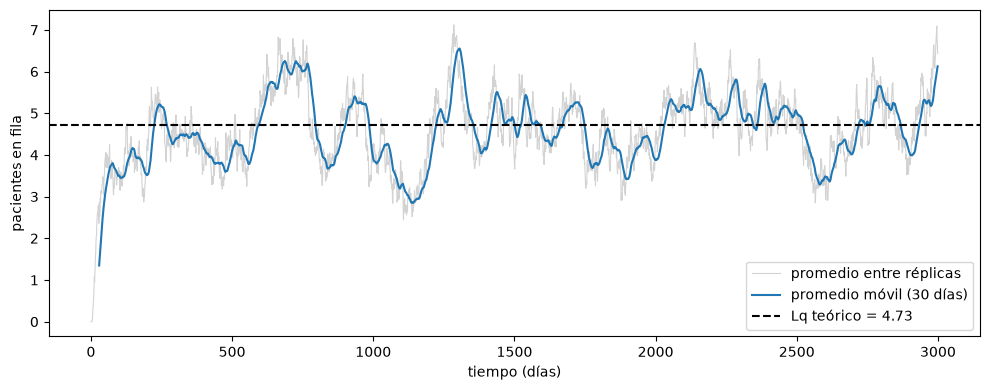

día   30: promedio móvil = 1.44
día   60: promedio móvil = 3.46
día  100: promedio móvil = 3.50
día  150: promedio móvil = 4.15
día  200: promedio móvil = 3.54
día  300: promedio móvil = 4.37
día  500: promedio móvil = 4.11


In [10]:
rejilla = np.arange(0, 3000, 1.0)
_, d_w = simulador.replicas(LAM, MU, C, 3000, 0, 99, "espera", 100, rejilla=rejilla)
lq_prom = d_w["Lq_t"].mean(axis=0)
VENTANA = 30
lq_movil = np.convolve(lq_prom, np.ones(VENTANA) / VENTANA, mode="valid")
t_movil = rejilla[VENTANA - 1:]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(rejilla, lq_prom, color="lightgray", lw=0.8, label="promedio entre réplicas")
ax.plot(t_movil, lq_movil, color="tab:blue", label=f"promedio móvil ({VENTANA} días)")
ax.axhline(t["Lq"], color="k", ls="--", label=f"Lq teórico = {t['Lq']:.2f}")
ax.set_xlabel("tiempo (días)")
ax.set_ylabel("pacientes en fila")
ax.legend()
fig.tight_layout()
fig.savefig("figuras/calentamiento.png", dpi=150)
plt.show()

for dia in [30, 60, 100, 150, 200, 300, 500]:
    print(f"día {dia:>4}: promedio móvil = {lq_movil[dia - VENTANA + 1]:.2f}")

**RESULTADOS**

La fila sube desde cero y entra a la banda de fluctuaciones (entre 3 y 6 pacientes) alrededor del día 60. Después solo oscila alrededor del valor teórico, con ciclos lentos de 200 a 300 días.

- **Calentamiento: 200 días**, cerca de tres veces el tiempo que tarda la fila en estabilizarse.
- **Horizonte: 5200 días** (5000 observados), para que cada réplica contenga unos 20 ciclos de fluctuación.

### Comparación con la teoría

Se corren 30 réplicas por variante con el calentamiento y el horizonte elegidos. Para cada medida se reporta la media, el IC del 95% y si el valor teórico cae dentro.

In [11]:
CALENTAMIENTO = 200
HORIZONTE = CALENTAMIENTO + 5000
N_REP = 30

res_e, dat_e = simulador.replicas(LAM, MU, C, HORIZONTE, CALENTAMIENTO, 2026, "espera", N_REP)
res_p, dat_p = simulador.replicas(LAM, MU, C, HORIZONTE, CALENTAMIENTO, 2027, "perdida", N_REP)

teoria_e = {"L": t["L"], "Lq": t["Lq"], "Wq": t["Wq"], "W": t["W"], "utilizacion": t["rho"],
            "prob_esperar": t["C"]}
teoria_p = {"L": s["L"], "W": s["W"], "utilizacion": s["L"] / C, "prob_bloqueo": s["B"],
            "tasa_ingresos": s["lam_ef"]}


def tabla(res, teoria):
    print(f"{'Medida':<15}{'Teoría':>9}{'Media':>9}{'IC95 inf':>10}{'IC95 sup':>10}  Dentro")
    for m, v in teoria.items():
        lo, hi = res[m]["ic95"]
        print(f"{m:<15}{v:9.4f}{res[m]['media']:9.4f}{lo:10.4f}{hi:10.4f}  {'sí' if lo <= v <= hi else 'no'}")


print("CON ESPERA (tiempos en días)")
tabla(res_e, teoria_e)
print(f"Wq = {res_e['Wq']['media'] * HORAS:.2f} h (teoría {t['Wq'] * HORAS:.2f} h)")
print()
print("SIN ESPERA")
tabla(res_p, teoria_p)

CON ESPERA (tiempos en días)
Medida            Teoría    Media  IC95 inf  IC95 sup  Dentro
L                19.9290  19.6189   19.2764   19.9614  sí
Lq                4.7290   4.4553    4.1453    4.7653  sí
Wq                1.2445   1.1738    1.0929    1.2548  sí
W                 5.2445   5.1705    5.0841    5.2569  sí
utilizacion       0.8941   0.8920    0.8893    0.8946  sí
prob_esperar      0.5600   0.5517    0.5421    0.5613  sí
Wq = 28.17 h (teoría 29.87 h)

SIN ESPERA
Medida            Teoría    Media  IC95 inf  IC95 sup  Dentro
L                13.3949  13.3834   13.3509   13.4158  sí
W                 4.0000   3.9966    3.9852    4.0080  sí
utilizacion       0.7879   0.7873    0.7853    0.7892  sí
prob_bloqueo      0.1188   0.1183    0.1166    0.1200  sí
tasa_ingresos     3.3487   3.3486    3.3417    3.3555  sí


**RESULTADOS**

La teoría cae dentro del IC del 95% en las 11 medidas. La espera simulada es de 28.17 h frente a 29.87 h teóricas. Las medidas de la fila tienen los intervalos más anchos porque la fila cambia lentamente y sus valores están muy correlacionados en el tiempo.

### Ley de Little con datos simulados

Se usan solo cantidades simuladas: $L$ y $L_q$ (promedios en el tiempo), $W$ y $W_q$ (promedios por paciente) y las tasas observadas de llegadas ($\hat\lambda$) e ingresos ($\hat\lambda_{ef}$).

In [12]:
def error(x, y):
    return abs(x - y) / y


L, Lq = res_e["L"]["media"], res_e["Lq"]["media"]
lam_hat, W, Wq = res_e["tasa_llegadas"]["media"], res_e["W"]["media"], res_e["Wq"]["media"]
print("CON ESPERA")
print(f"  L  = {L:.4f}  vs  lam_hat * W  = {lam_hat * W:.4f}  (error {error(lam_hat * W, L):.3%})")
print(f"  Lq = {Lq:.4f}  vs  lam_hat * Wq = {lam_hat * Wq:.4f}  (error {error(lam_hat * Wq, Lq):.3%})")

L, lam_ef, W = res_p["L"]["media"], res_p["tasa_ingresos"]["media"], res_p["W"]["media"]
lam_hat = res_p["tasa_llegadas"]["media"]
print("SIN ESPERA")
print(f"  L  = {L:.4f}  vs  lam_ef_hat * W = {lam_ef * W:.4f}  (error {error(lam_ef * W, L):.3%})")
print(f"  Con lam_hat en lugar de lam_ef: {lam_hat * W:.4f}  (error {error(lam_hat * W, L):.3%})")

CON ESPERA
  L  = 19.6189  vs  lam_hat * W  = 19.6164  (error 0.013%)
  Lq = 4.4553  vs  lam_hat * Wq = 4.4534  (error 0.044%)
SIN ESPERA
  L  = 13.3834  vs  lam_ef_hat * W = 13.3832  (error 0.001%)
  Con lam_hat en lugar de lam_ef: 15.1798  (error 13.423%)


**RESULTADOS**

| Variante | Relación | Error relativo |
|---|---|---|
| Con espera | $L = \hat\lambda W$ | 0.013% |
| Con espera | $L_q = \hat\lambda W_q$ | 0.044% |
| Sin espera | $L = \hat\lambda_{ef} W$ | 0.001% |
| Sin espera | $L = \hat\lambda W$ (incorrecta) | 13.4% |

Little se cumple con los datos simulados. El pequeño error restante se debe a los bordes de la ventana: el área se mide entre 200 y 5200 días, mientras que las esperas se miden por paciente.

### Afirmaciones del agente

Se vuelve a correr el código de la IA tal como fue entregado, con sus mismas semillas, para revisar sus afirmaciones.

In [13]:
r_ia_e = simulador_ia.replicas(LAM, MU, C, 2000, 200, 2026, "espera", 30)
r_ia_p = simulador_ia.replicas(LAM, MU, C, 2000, 200, 2027, "perdida", 30)
print(f"IC95 de prob_bloqueo (IA, con espera): {r_ia_e['prob_bloqueo']['ic95']}")
print(f"IC95 de Wq (IA, sin espera): {r_ia_p['Wq']['ic95']}")
for nombre, r in [("IA, 1800 días", r_ia_e["Lq"]), ("corregido, 5000 días", res_e["Lq"])]:
    lo, hi = r["ic95"]
    print(f"Semiancho relativo del IC de Lq ({nombre}): {(hi - lo) / 2 / r['media']:.1%}")

IC95 de prob_bloqueo (IA, con espera): (0.0, 0.0)
IC95 de Wq (IA, sin espera): (0.0, 0.0)
Semiancho relativo del IC de Lq (IA, 1800 días): 12.2%
Semiancho relativo del IC de Lq (corregido, 5000 días): 7.0%


**RESULTADOS**

| Afirmación del agente | Resultado |
|---|---|
| "Las verificaciones respaldan que el simulador es correcto" | Confirmada: pasa las pruebas 1 a 4 |
| "Todos los valores teóricos quedaron dentro de sus respectivos intervalos" | Confirmada, pero exagerada: 4 de las 12 comparaciones son triviales (IC $(0, 0)$ contra teoría $0$, como $B$ en la variante con espera o $W_q$ en la variante sin espera). Solo 8 son comparaciones reales |
| "Pasó 64 comparaciones contra un cálculo independiente por paciente" | **No se pudo confirmar**: el código entregado no contiene esas pruebas |
| "El código calcula las referencias mediante $B = \frac{a^c/c!}{\sum a^k/k!}$" | **Incorrecta**: el código usa la recurrencia de Erlang B (líneas 181–183). El resultado es el mismo, pero la descripción no corresponde al código |

Además, con el horizonte del agente el semiancho del IC de $L_q$ es del 12.2%; con el horizonte elegido baja a 7.0%.

## Task 2.1. Predicciones

Las predicciones y su razonamiento están en el documento. Se escribieron antes de ejecutar las simulaciones de este task. Aquí solo se evalúan las fórmulas con los parámetros del grupo.

- Allen y Cunneen: $W_q \approx W_q^{M/M/c}\,\frac{1 + C_S^2}{2}$
- Cierre: $T_d = \dfrac{T_b\,(\lambda - (c - k_{off})\mu)}{c\mu - \lambda}$
- Estancia 25% más larga: $B(c, \lambda/\mu')$ con $1/\mu' = 1.25/\mu$

In [14]:
TB, K_OFF = 7, k_off
pred_wq = {cs: t["Wq"] * HORAS * (1 + cs**2) / 2 for cs in (0, 1, 2)}
for cs, w in pred_wq.items():
    print(f"C_S = {cs}: Wq predicho = {w:.2f} h")

pred_td = TB * (LAM - (C - K_OFF) * MU) / (C * MU - LAM)
print(f"Td predicho = {pred_td:.2f} días")

MU_LARGA = MU / 1.25
pred_b = erlang_b(C, LAM / MU_LARGA)
print(f"B predicho = {pred_b:.4f} ({pred_b / s['B']:.2f} veces el actual)")

C_S = 0: Wq predicho = 14.93 h
C_S = 1: Wq predicho = 29.87 h
C_S = 2: Wq predicho = 74.67 h
Td predicho = 12.44 días
B predicho = 0.2282 (1.92 veces el actual)


**RESULTADOS**

Los valores coinciden con los del documento: $W_q$ de 14.93, 29.87 y 74.67 h; $T_d = 12.4$ días; y $B = 0.2282$, 1.92 veces el actual.

## Task 2.2. Variabilidad de la estancia

Se simula la variante con espera con tres distribuciones de la estancia, todas con media $1/\mu = 4$ días:

- Determinista ($C_S = 0$): siempre 4 días.
- Exponencial ($C_S = 1$).
- Lognormal ($C_S = 2$): $s^2 = \ln(1 + C_S^2)$, $m = \ln(1/\mu) - s^2/2$.

Se usan el mismo calentamiento, horizonte y número de réplicas del Task 1.4.

In [15]:
estancias = {
    0: simulador.estancia_determinista(MU),
    1: simulador.estancia_exponencial(MU),
    2: simulador.estancia_lognormal(MU, 2),
}
res_cs = {}
print(f"{'C_S':<5}{'Predicho (h)':>13}{'Simulado (h)':>14}{'IC95 (h)':>20}{'Error rel.':>12}")
for cs, est in estancias.items():
    r, _ = simulador.replicas(LAM, MU, C, HORIZONTE, CALENTAMIENTO, 300 + cs, "espera", N_REP,
                              estancia=est)
    res_cs[cs] = r
    wq = r["Wq"]["media"] * HORAS
    lo, hi = (x * HORAS for x in r["Wq"]["ic95"])
    print(f"{cs:<5}{pred_wq[cs]:13.2f}{wq:14.2f}{f'({lo:.2f}, {hi:.2f})':>20}{abs(pred_wq[cs] - wq) / wq:12.1%}")

C_S   Predicho (h)  Simulado (h)            IC95 (h)  Error rel.


0            14.93         16.32      (15.13, 17.52)        8.5%


1            29.87         28.58      (26.95, 30.21)        4.5%


2            74.67         64.09      (53.07, 75.10)       16.5%


**RESULTADOS**

| $C_S$ | Predicho (h) | Simulado (h) | IC95 (h) | Error relativo |
|---|---|---|---|---|
| 0 | 14.93 | 16.32 | (15.13, 17.52) | 8.5% |
| 1 | 29.87 | 28.58 | (26.95, 30.21) | 4.5% |
| 2 | 74.67 | 64.09 | (53.07, 75.10) | 16.5% |

- Con $C_S = 1$ la fórmula es exacta (M/M/$c$); el 4.5% es ruido de simulación, porque la teoría cae dentro del IC.
- Con $C_S = 0$ la aproximación subestima la espera en 8.5%, y la predicción queda fuera del IC.
- **La aproximación falla más con $C_S = 2$** (16.5%) y sobreestima la espera. El IC es muy ancho ($\pm 17\%$): con estancias tan variables, unas pocas estancias muy largas dominan cada réplica.

**Por qué la variabilidad empeora la espera:** con la misma media de 4 días, la espera pasa de 16.3 h a 28.6 h y a 64.1 h al aumentar $C_S$. Cuando la estancia varía mucho, algunos pacientes ocupan su cama durante semanas. Mientras tanto, las altas se agrupan de forma irregular y hay periodos largos sin camas libres, en los que la fila crece. Con estancias fijas, las altas son regulares y la fila se vacía de forma más pareja.

## Task 2.3. Cierre parcial de camas

Entre $t_0 = 300$ días (después del calentamiento) y $t_0 + T_b = 307$ días, la capacidad baja a $c - k_{off} = 12$ camas. Los pacientes que ya ocupan una cama la conservan hasta su alta; los nuevos ingresos esperan hasta que haya menos de 12 camas ocupadas.

Se registra la fila cada 0.1 días y se promedia entre réplicas. Se usan 1000 réplicas porque, con 100, el promedio fluctúa tanto alrededor del umbral $1.1\,L_q$ que el instante de cruce cambia mucho de una corrida a otra. Aun con 1000 réplicas el cruce es sensible al ruido, por lo que también se reporta un IC del 95% por bootstrap, remuestreando réplicas.

El tiempo de recuperación es el primer instante después de la reapertura en que la fila promedio es menor que $1.1\,L_q$ estacionario.

In [16]:
T0 = 300
N_CIERRE = 1000
rejilla_c = np.arange(T0 - 50, T0 + 250, 0.1)
despues = rejilla_c >= T0 + TB


def simular_cierre(estancia, semilla):
    """Devuelve la matriz réplica × tiempo con la fila registrada en `rejilla_c`."""
    _, d = simulador.replicas(LAM, MU, C, T0 + 300, CALENTAMIENTO, semilla, "espera", N_CIERRE,
                              estancia=estancia, rejilla=rejilla_c, cierre=(T0, T0 + TB, K_OFF))
    return d["Lq_t"]


def recuperacion(lq_medio, lq_estacionario):
    """Primer tiempo tras la reapertura en que `lq_medio` < 1.1 · `lq_estacionario`."""
    i = np.argmax(despues & (lq_medio < 1.1 * lq_estacionario))
    return rejilla_c[i] - (T0 + TB)


def ic_bootstrap(matriz, lq_estacionario, n_boot=200, semilla=0):
    """IC del 95% del tiempo de recuperación remuestreando réplicas con reemplazo."""
    rng = np.random.default_rng(semilla)
    n = len(matriz)
    tiempos = [recuperacion(matriz[rng.integers(0, n, n)].mean(axis=0), lq_estacionario)
               for _ in range(n_boot)]
    return np.percentile(tiempos, [2.5, 97.5])


lq_exp = t["Lq"]
lq_det = res_cs[0]["Lq"]["media"]
m_exp = simular_cierre(estancias[1], 400)
m_det = simular_cierre(estancias[0], 401)
curva_exp, curva_det = m_exp.mean(axis=0), m_det.mean(axis=0)
trec_exp, trec_det = recuperacion(curva_exp, lq_exp), recuperacion(curva_det, lq_det)
ic_exp, ic_det = ic_bootstrap(m_exp, lq_exp), ic_bootstrap(m_det, lq_det)

print(f"Td de la fórmula: {pred_td:.1f} días")
print(f"Exponencial:  Lq = {lq_exp:.2f}, pico = {curva_exp.max():.2f}, recuperación = {trec_exp:.1f} días, "
      f"IC95 bootstrap = ({ic_exp[0]:.1f}, {ic_exp[1]:.1f})")
print(f"Determinista: Lq = {lq_det:.2f}, pico = {curva_det.max():.2f}, recuperación = {trec_det:.1f} días, "
      f"IC95 bootstrap = ({ic_det[0]:.1f}, {ic_det[1]:.1f})")
print(f"Pico según el modelo de acumulación: Lq + Q = {lq_exp:.2f} + {TB * (LAM - (C - K_OFF) * MU):.2f}"
      f" = {lq_exp + TB * (LAM - (C - K_OFF) * MU):.2f}")
print(f"Fila justo antes y después de la reapertura (exponencial): "
      f"{curva_exp[rejilla_c < T0 + TB][-1]:.2f} -> {curva_exp[despues][0]:.2f}")

Td de la fórmula: 12.4 días
Exponencial:  Lq = 4.73, pico = 13.50, recuperación = 67.3 días, IC95 bootstrap = (48.2, 109.5)
Determinista: Lq = 2.59, pico = 9.30, recuperación = 24.5 días, IC95 bootstrap = (24.1, 44.1)
Pico según el modelo de acumulación: Lq + Q = 4.73 + 5.60 = 10.33
Fila justo antes y después de la reapertura (exponencial): 13.50 -> 9.22


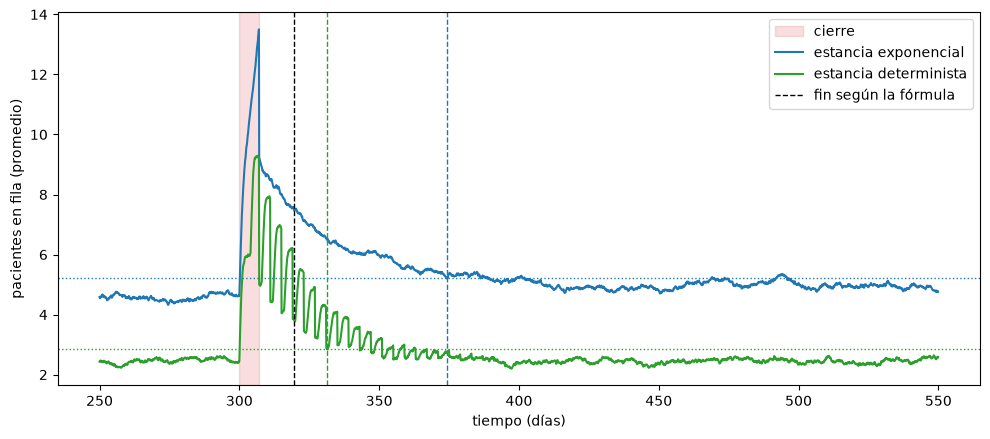

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(T0, T0 + TB, color="tab:red", alpha=0.15, label="cierre")
for curva, lq, trec, color, nombre in [(curva_exp, lq_exp, trec_exp, "tab:blue", "exponencial"),
                                       (curva_det, lq_det, trec_det, "tab:green", "determinista")]:
    ax.plot(rejilla_c, curva, color=color, label=f"estancia {nombre}")
    ax.axhline(1.1 * lq, color=color, ls=":", lw=1)
    ax.axvline(T0 + TB + trec, color=color, ls="--", lw=1)
ax.axvline(T0 + TB + pred_td, color="k", ls="--", lw=1, label="fin según la fórmula")
ax.set_xlabel("tiempo (días)")
ax.set_ylabel("pacientes en fila (promedio)")
ax.legend()
fig.tight_layout()
fig.savefig("figuras/cierre.png", dpi=150)
plt.show()

**RESULTADOS**

| | Fórmula | Simulado, exponencial | Simulado, determinista |
|---|---|---|---|
| Fila máxima | 10.33 | 13.50 | 9.30 |
| Tiempo de recuperación (días) | 12.4 | 67.3 (IC95: 48.2 a 109.5) | 24.5 (IC95: 24.1 a 44.1) |

La simulación tarda unas 5 veces más que la fórmula en recuperarse. La discrepancia viene de dos partes del modelo de acumulación:

1. **Vaciado a tasa constante.** La fórmula supone que la fila baja a 0.45 pacientes/día hasta desaparecer el exceso. En la simulación la fila baja rápido al principio y luego cada vez más despacio: cuando está cerca de su nivel normal, las fluctuaciones aleatorias la empujan hacia arriba casi tanto como hacia abajo. Por eso la curva pasa muchos días apenas por encima del umbral.
2. **Acumulación durante el cierre.** La fórmula supone que la fila crece a $\lambda - 12\mu = 0.8$ pacientes/día. Al iniciar el cierre había unas 15 camas ocupadas, y no se admite a nadie hasta que bajan a 12, así que la fila crece a $\lambda = 3.8$ al principio. El pico es de 13.5 en lugar de 10.3.

**Efecto de la variabilidad:** con estancia determinista, la recuperación baja de 67.3 a 24.5 días. Respecto a la fórmula, $(67.3 - 24.5)/(67.3 - 12.4) = 78\%$ de la diferencia se atribuye a la variabilidad de la estancia. El 22% restante (12 días) se debe a las llegadas aleatorias y a la mayor acumulación al inicio del cierre.

Con estancia determinista la curva tiene forma de sierra: los pacientes admitidos juntos en la reapertura salen juntos cada 4 días.

## Task 2.4. Estancia 25% más larga

Se simula la variante sin espera con estancia media de 5 días ($\mu = 0.2$) y 30 réplicas.

In [18]:
r_larga, _ = simulador.replicas(LAM, MU_LARGA, C, HORIZONTE, CALENTAMIENTO, 500, "perdida", N_REP)
b_sim = r_larga["prob_bloqueo"]["media"]
lo, hi = r_larga["prob_bloqueo"]["ic95"]
print(f"B predicho = {pred_b:.4f}")
print(f"B simulado = {b_sim:.4f}, IC95 = ({lo:.4f}, {hi:.4f})")
print(f"Error relativo = {abs(pred_b - b_sim) / b_sim:.2%}")
print(f"Aumento simulado = {b_sim / res_p['prob_bloqueo']['media']:.2f} veces")

B predicho = 0.2282
B simulado = 0.2282, IC95 = (0.2266, 0.2298)
Error relativo = 0.02%
Aumento simulado = 1.93 veces


**RESULTADOS**

El bloqueo simulado es 0.2282, igual a la predicción con un error del 0.02%, y es 1.93 veces el actual (predicción: 1.92).

### Balance de las predicciones

| Predicción (Task 2.1) | Predicho | Simulado | Error relativo | Explicación de la diferencia |
|---|---|---|---|---|
| a. $W_q$ con $C_S = 0$ | 14.93 h | 16.32 h | 8.5% | La aproximación subestima la espera de las estancias fijas |
| a. $W_q$ con $C_S = 1$ | 29.87 h | 28.58 h | 4.5% | Ruido de simulación; la teoría está dentro del IC |
| a. $W_q$ con $C_S = 2$ | 74.67 h | 64.09 h | 16.5% | La fórmula solo usa media y varianza; ignora la cola larga de la lognormal. Se acertó que sería el caso menos preciso |
| b. $T_d$ del cierre | 12.4 días (se predijo que la simulación daría más, cerca de 20) | 67.3 días | 81.5% respecto a la fórmula | Se acertó la dirección, pero no la magnitud. El vaciado no es a tasa constante, y al iniciar el cierre las camas ocupadas aumentan la acumulación (se había predicho lo contrario) |
| c. $B$ con estancia de 5 días | 0.2282 (1.92 veces) | 0.2282 (1.93 veces) | 0.02% | Erlang B es exacta para la variante sin espera |

### Hallazgo principal

Lo más sorprendente fue el tiempo de recuperación tras el cierre: una semana con 5 camas menos afecta la fila durante más de dos meses, unas 5 veces lo que indica la fórmula. Las fórmulas de régimen estacionario (Erlang B y C) resultaron confiables, incluso con aproximaciones como la de Allen y Cunneen. En cambio, las fórmulas de acumulación para transiciones deben tomarse solo como un límite optimista, y esos casos deben simularse.